# Modeling — Performances en Powerlifting
4 modèles de base pour estimer les performances initiales.

**Insights EDA :**
- `BodyweightKg` est la variable la plus corrélée (r=0.66)
- `Sex` et `Equipment` ont un fort impact sur la médiane
- `MeetYear` corrélé négativement (-0.12)
- 68 outliers < 100 kg, 282 > 1000 kg
- Pas de valeurs manquantes

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import cross_val_score, KFold
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

train = pd.read_csv('train.csv')
test  = pd.read_csv('test.csv')
print('Train:', train.shape, '| Test:', test.shape)

Train: (105000, 18) | Test: (45000, 17)


## 1. Préparation des features

In [2]:
# Features retenues d'après l'EDA
NUM_FEATURES = ['Age', 'BodyweightKg', 'MeetYear']
CAT_FEATURES = ['Sex', 'Equipment', 'Tested', 'AgeClass', 'WeightClassKg',
                'Federation', 'ParentFederation', 'Country', 'Sanctioned']

ALL_FEATURES = NUM_FEATURES + CAT_FEATURES
TARGET = 'TotalKg'

X_raw = train[ALL_FEATURES].copy()
y     = train[TARGET].copy()
X_test_raw = test[ALL_FEATURES].copy()

# Encoder les catégorielles
enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_raw[CAT_FEATURES] = enc.fit_transform(X_raw[CAT_FEATURES])
X_test_raw[CAT_FEATURES] = enc.transform(X_test_raw[CAT_FEATURES])

X = X_raw.values
X_test = X_test_raw.values

print('Features shape:', X.shape)
print('Target — mean: {:.1f}, std: {:.1f}'.format(y.mean(), y.std()))

Features shape: (105000, 12)
Target — mean: 493.0, std: 171.4


## 2. Validation croisée — 4 modèles
Métrique : **RMSE** (même unité que TotalKg, en kg)

In [3]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Ridge':             Ridge(alpha=1.0),
    'DecisionTree':      DecisionTreeRegressor(max_depth=10, random_state=42),
    'RandomForest':      RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42),
    'GradientBoosting':  GradientBoostingRegressor(n_estimators=100, max_depth=5, random_state=42),
}

results = {}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=kf,
                             scoring='neg_root_mean_squared_error', n_jobs=-1)
    rmse_scores = -scores
    results[name] = {'mean': rmse_scores.mean(), 'std': rmse_scores.std()}
    print(f'{name:22s}  RMSE = {rmse_scores.mean():.2f} ± {rmse_scores.std():.2f}')

Ridge                   RMSE = 105.39 ± 0.31
DecisionTree            RMSE = 88.48 ± 0.54


Exception ignored in: <function ResourceTracker.__del__ at 0x102e65bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x104771bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x104d15bc0>
Traceback (most recent call last

RandomForest            RMSE = 85.16 ± 0.54
GradientBoosting        RMSE = 82.60 ± 0.41


## 3. Comparaison visuelle

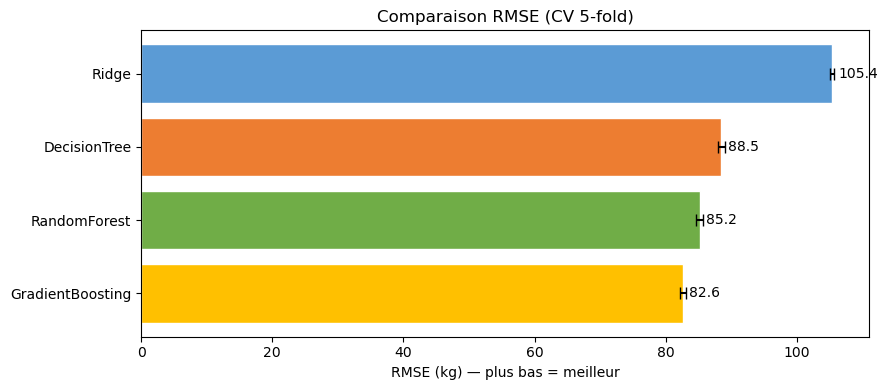

In [4]:
names  = list(results.keys())
means  = [results[n]['mean'] for n in names]
stds   = [results[n]['std']  for n in names]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(names, means, xerr=stds, color=['#5B9BD5','#ED7D31','#70AD47','#FFC000'],
               capsize=4, edgecolor='white')
for bar, val in zip(bars, means):
    ax.text(val + 1, bar.get_y() + bar.get_height()/2, f'{val:.1f}',
            va='center', fontsize=10)
ax.set_xlabel('RMSE (kg) — plus bas = meilleur')
ax.set_title('Comparaison RMSE (CV 5-fold)')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 4. Feature Importance (meilleur modèle)

Meilleur modèle : GradientBoosting  (RMSE = 82.60)


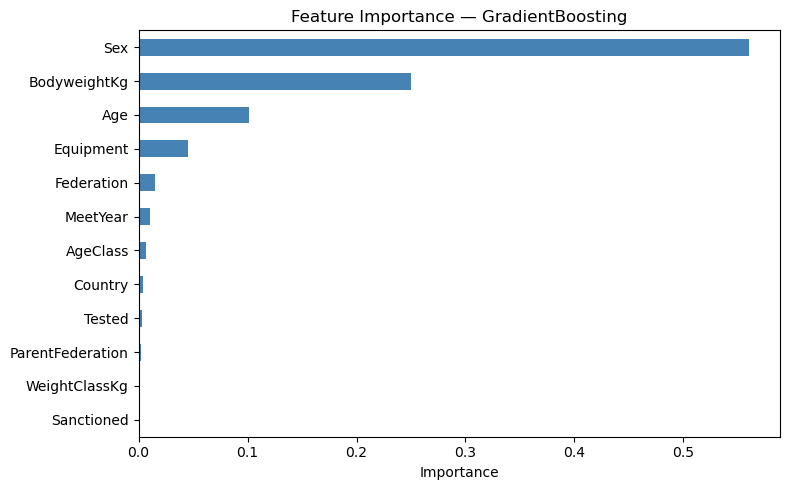

In [5]:
# Entraîner le meilleur modèle sur tout le train
best_name = min(results, key=lambda n: results[n]['mean'])
best_model = models[best_name]
best_model.fit(X, y)
print(f'Meilleur modèle : {best_name}  (RMSE = {results[best_name]["mean"]:.2f})')

if hasattr(best_model, 'feature_importances_'):
    importances = pd.Series(best_model.feature_importances_, index=ALL_FEATURES)
    importances = importances.sort_values(ascending=True)

    fig, ax = plt.subplots(figsize=(8, 5))
    importances.plot(kind='barh', ax=ax, color='steelblue')
    ax.set_title(f'Feature Importance — {best_name}')
    ax.set_xlabel('Importance')
    plt.tight_layout()
    plt.show()
elif hasattr(best_model, 'coef_'):
    coefs = pd.Series(np.abs(best_model.coef_), index=ALL_FEATURES).sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=(8, 5))
    coefs.plot(kind='barh', ax=ax, color='steelblue')
    ax.set_title(f'|Coefficients| — {best_name}')
    plt.tight_layout()
    plt.show()

## 5. Prédictions & soumission

In [ ]:
preds = best_model.predict(X_test)
preds = np.clip(preds, 0, None)  # pas de valeurs négatives

submission = pd.DataFrame({'id': test['id'], 'TotalKg': preds})
submission.to_csv('submission_baseline.csv', index=False)

print('Submission sauvegardée : submission_baseline.csv')
print(submission['TotalKg'].describe().round(2))

Submission sauvegardée : submission_baseline.csv
count    45000.00
mean       494.97
std        147.93
min         99.99
25%        356.63
50%        516.48
75%        605.17
max       1074.98
Name: TotalKg, dtype: float64


Exception ignored in: <function ResourceTracker.__del__ at 0x107de9bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x107765bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x104fd1bc0>
Traceback (most recent call last

## 6. Résumé

| Modèle | Avantages | Limites |
|--------|-----------|--------|
| **Ridge** | Rapide, interprétable | Linéaire, ne capture pas les interactions |
| **DecisionTree** | Interprétable | Overfitting si profond |
| **RandomForest** | Robuste, bon par défaut | Lent, mémoire élevée |
| **GradientBoosting** | Généralement le plus précis | Plus lent à entraîner |

**Prochaines étapes :** feature engineering (`Sex×Equipment`, `WeightClass` numérique), XGBoost/LightGBM, tuning des hyperparamètres.